# Predicting Turbofan Engine Life Cycles - NASA C-MAPSS

- **Objective:** Predict remaining cycles of an engine.
- **Data:** Nasa C-MAPSS-1 Turbofan Engine Degradation.
- **Generated by simulation:** Commercial Modular Aero-Propulsion System Simulation.
- **For the PHM08 Challenge:** Prognostic & Health Management 2008. Since then, it has become the global benchmark for predictive maintenance in the industrial field.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np


processed_dir = Path("../data")
file_pat_fd001 = processed_dir / f"labeled_train_FD001.csv"
file_pat_fd002 = processed_dir / f"labeled_train_FD002.csv"
file_pat_fd003 = processed_dir / f"labeled_train_FD003.csv"
file_pat_fd004 = processed_dir / f"labeled_train_FD004.csv"
train_df = pd.read_csv(file_pat_fd001)

## Datasets

- Subsets: FD001, FD002, FD003, FD004
- Categories: train, test, RUL

| Dataset | Train trajectories | Test trajectories | Conditions | Fault Modes |
|---|---:|---:|---|---|
| FD001 | 100 | 100 | ONE (Sea Level) | ONE (HPC Degradation) |
| FD002 | 260 | 259 | SIX | ONE (HPC Degradation) |
| FD003 | 100 | 100 | ONE (Sea Level) | TWO (HPC Degradation, Fan Degradation) |
| FD004 | 248 | 249 | SIX | TWO (HPC Degradation, Fan Degradation) |


### General Notes

- Each engine starts with different levels of initial wear and manufacturing variation.
- In the training set, each engine runs until failure. In the test set, the data is truncated before the failure occurs.
- The RUL (Remaining Useful Life) column contains the remaining cycles for the test data.
- Data is contaminated with noise in the sensors.

### Columns

#### Identification and operating conditions

| Column | Description |
|---|---|
| `engine_id` | Engine identifier. |
| `Operational Setting 1` | Flight altitude. |
| `Operational Setting 2` | Mach number: aircraft speed relative to the speed of sound. |
| `Operational Setting 3` | Throttle resolver angle, related to engine power demand. |

#### Sensors

| Sensor | Variable | Description |
|---:|---|---|
| 1 | `T2` | Total temperature at the fan inlet. |
| 2 | `T24` | Total temperature at the outlet of the low-pressure compressor (LPC). |
| 3 | `T30` | Total temperature at the outlet of the high-pressure compressor (HPC). |
| 4 | `T50` | Total temperature at the outlet of the low-pressure turbine (LPT). |
| 5 | `P2` | Pressure at the fan inlet. |
| 6 | `P15` | Total pressure in the bypass duct. |
| 7 | `P30` | Total pressure at the outlet of the high-pressure compressor. |
| 8 | `Nf` | Physical fan speed. |
| 9 | `Nc` | Physical core speed. |
| 10 | `epr` | Engine pressure ratio. |
| 11 | `Ps30` | Static pressure at the outlet of the high-pressure compressor. |
| 12 | `phi` | Ratio between fuel flow and `Ps30`. |
| 13 | `NRf` | Corrected fan speed. |
| 14 | `NRc` | Corrected core speed. |
| 15 | `BPR` | Bypass ratio. |
| 16 | `farB` | Fuel-to-air ratio in the combustor. |
| 17 | `htBleed` | Enthalpy bleed. |
| 18 | `Nf_dmd` | Demanded fan speed. |
| 19 | `PCNfR_dmd` | Demanded corrected fan speed, expressed as a percentage. |
| 20 | `W31` | High-pressure turbine (HPT) cooling flow. |
| 21 | `W32` | Low-pressure turbine (LPT) cooling flow. |


### Datasets sumary

| subset | category | rows | engines | missing_values | duplicate_rows | cycles_continuous | cycles_min | cycles_mean | cycles_max |
|---|---|---:|---:|---:|---:|---|---:|---:|---:|
| FD001 | train | 20631 | 100 | 0 | 0 | True | 128 | 206.3 | 362 |
| FD001 | test | 13096 | 100 | 0 | 0 | True | 31 | 131.0 | 303 |
| FD002 | train | 53759 | 260 | 0 | 0 | True | 128 | 206.8 | 378 |
| FD002 | test | 33991 | 259 | 0 | 0 | True | 21 | 131.2 | 367 |
| FD003 | train | 24720 | 100 | 0 | 0 | True | 145 | 247.2 | 525 |
| FD003 | test | 16596 | 100 | 0 | 0 | True | 38 | 166.0 | 475 |
| FD004 | train | 61249 | 249 | 0 | 0 | True | 128 | 246.0 | 543 |
| FD004 | test | 41214 | 248 | 0 | 0 | True | 19 | 166.2 | 486 |

# Fligth settings per dataset

For dataset FD001 and FD003 values are constants since they are simulated in just one mode of flight

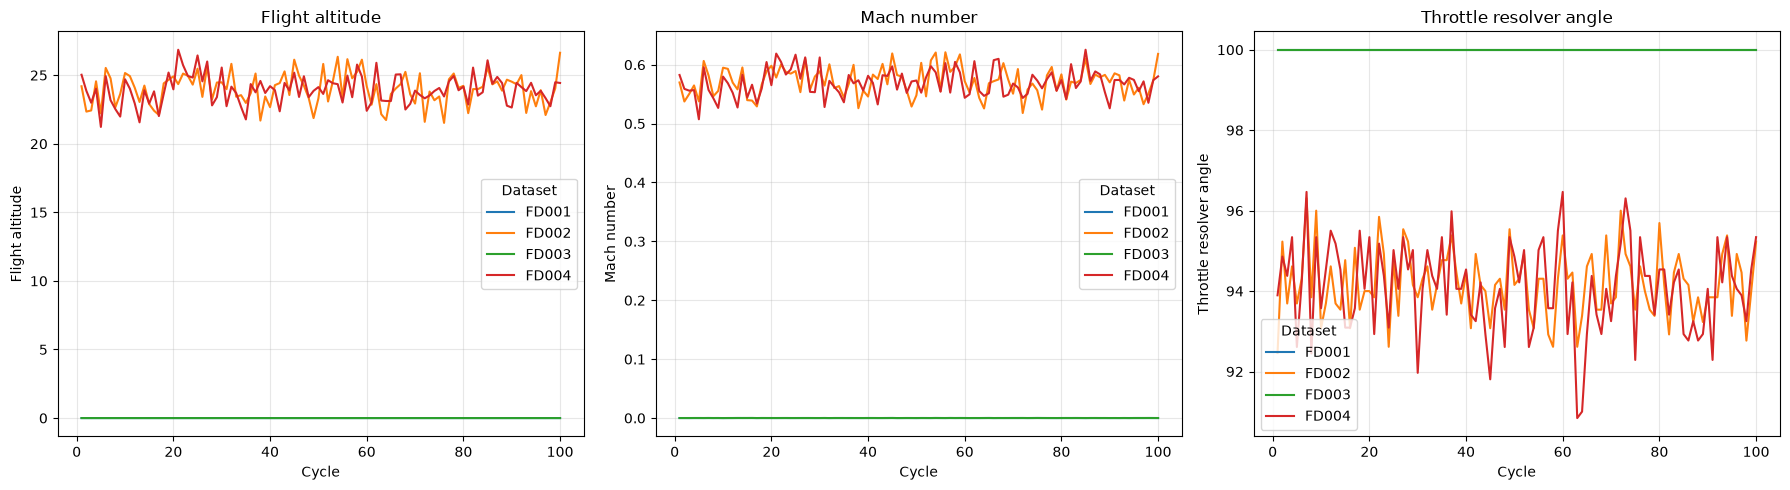

In [ ]:

subsets = ["FD001", "FD002", "FD003", "FD004"]
settings = ["setting_1", "setting_2", "setting_3"]

train_data = {}

for subset in subsets:
    file_path = processed_dir / f"labeled_train_{subset}.csv"
    df = pd.read_csv(file_path)

    train_data[subset] = (
        df[df["cycle"] <= 100]
        .groupby("cycle", as_index=False)[settings]
        .mean()
        .sort_values("cycle")
    )

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

setting_labels = {
    "setting_1": "Flight altitude",
    "setting_2": "Mach number",
    "setting_3": "Throttle resolver angle",
}

for ax, setting in zip(axes, ["setting_1", "setting_2", "setting_3"]):
    for subset in subsets:
        data = train_data[subset]
        ax.plot(data["cycle"], data[setting], label=subset)

    ax.set_title(setting_labels[setting])
    ax.set_xlabel("Cycle")
    ax.set_ylabel(setting_labels[setting])
    ax.legend(title="Dataset")
    ax.grid(True, alpha=0.3)

fig.tight_layout()
plt.show()
plt.show()



# Objective

<p align="center"><font size="+2">RUL = Max cycle − current cycle</font></p>

# Baseline 
- Models: Ridge
- Scaling: Since the sensors measure different units, standardization is applied to avoid giving more weight to one variable over another.
- Cross-validation: GroupKFold is used to ensure that engines are split, not individual cycles.
- Metrics: MSE / RMSE and R²
- Cross-validation use: It evaluates two metrics simultaneously, unlike using cross_validate_score alone.


## Model Results

- **Ridge**: alpha = 100.0, MSE = 2029.6433, RMSE = 44.9630, R² = 0.5732

# TODO

## Model risks and considerations

- Too many features: Are there too many columns for the model to learn effectively? In this context, "too many" means a large feature space relative to the available data, which can increase variance and make generalization harder.
- Correlated features: In physical systems, sensors often capture related signals. Some variables may be highly correlated because they measure related components or outputs of the same system. This can reduce interpretability and create redundancy.
- Irrelevant features: The dataset contains noisy sensor measurements. Some columns may contribute little to the target variable or may add noise instead of useful information.
- Effect of alpha: What is the impact of alpha in the regularization term? This parameter controls the strength of the penalty. A larger alpha increases shrinkage, which can reduce overfitting but may also remove useful signal.
- Asymmetric penalty: The evaluation metric penalizes late predictions much more heavily than early predictions. A late prediction means that the model estimates a longer remaining useful life than the actual value, which can be more harmful operationally.

## Important note on the evaluation metric

The scoring function is asymmetric: it penalizes late predictions more strongly than early ones. This is important in predictive maintenance, because overestimating remaining useful life can lead to delayed interventions and higher risk of failure.


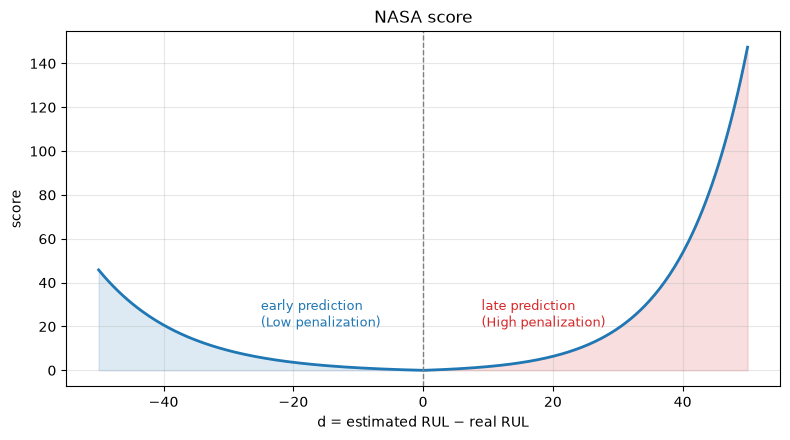

In [9]:
import numpy as np
import matplotlib.pyplot as plt

def nasa_score(d):
    """NASA score (Saxena et al. 2008). d = predicted RUL - true RUL."""
    d = np.asarray(d, dtype=float)
    return np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)


d_range = np.linspace(-50, 50, 400)
scores = nasa_score(d_range)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(d_range, scores, color="#1f77b4", linewidth=2)
ax.axvline(0, color="#7f7f7f", linewidth=1, linestyle="--")
ax.fill_between(d_range, scores, where=(d_range < 0), color="#1f77b4", alpha=0.15)
ax.fill_between(d_range, scores, where=(d_range >= 0), color="#d62728", alpha=0.15)

ax.set_title("NASA score")
ax.set_xlabel("d = estimated RUL − real RUL")
ax.set_ylabel("score")
ax.annotate("early prediction\n(Low penalization)", xy=(-10, nasa_score(-10)),
            xytext=(-25, 20), fontsize=9, color="#1f77b4")
ax.annotate("late prediction\n(High penalization)", xy=(10, nasa_score(10)),
            xytext=(9, 20), fontsize=9, color="#d62728")
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig("../outputs/nasa_score.png", dpi=150)
plt.show()

# Sensors analysis

Sensors that do not change: sensor_1, sensor_19, sensor_18, sensor_10, sensor_16, sensor_5


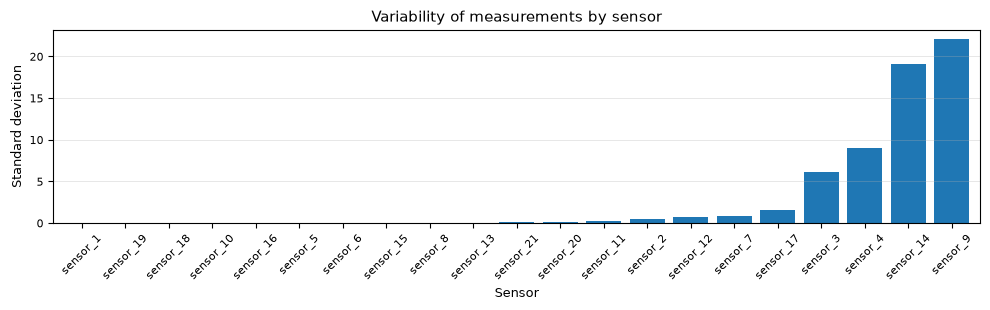

,std,unique_values
sensor_1,0.000000e+00,1
sensor_19,0.000000e+00,1
sensor_18,0.000000e+00,1
sensor_10,0.000000e+00,1
sensor_16,3.469531e-18,1
sensor_5,5.329200e-15,1
sensor_6,1.388985e-03,2
sensor_15,3.750504e-02,1918
sensor_8,7.098548e-02,53
sensor_13,7.191892e-02,56


In [5]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

def sensors_behaviour(df, sensor_cols=None):
    if sensor_cols is None:
        sensor_cols = [
            col for col in df.columns
            if col.lower().startswith("sensor")
        ]

    if not sensor_cols:
        raise ValueError(
            "No sensor columns were found. "
            "Pass their names via the sensor_cols parameter."
        )

    stats = pd.DataFrame({
        "std": df[sensor_cols].std(),
        "unique_values": df[sensor_cols].nunique(dropna=True),
    }).sort_values("std")

    constant_sensors = stats.index[stats["unique_values"] <= 1].tolist()

    fig, ax = plt.subplots(figsize=(10, 3.2))
    colors = [
        "#d62728" if sensor in constant_sensors else "#1f77b4"
        for sensor in stats.index
    ]

    stats["std"].plot(kind="bar", ax=ax, color=colors, width=0.8)
    ax.set_title("Variability of measurements by sensor", fontsize=11)
    ax.set_xlabel("Sensor", fontsize=9)
    ax.set_ylabel("Standard deviation", fontsize=9)
    ax.tick_params(axis="x", rotation=45, labelsize=8)
    ax.tick_params(axis="y", labelsize=8)
    ax.grid(axis="y", alpha=0.3, linewidth=0.7)

    if constant_sensors:
        print("Sensors that do not change:", ", ".join(constant_sensors))
    else:
        print("All sensors show variation.")

    fig.tight_layout()
    plt.show()

    return stats


sensors_behaviour(train_df)

In [6]:
removed_sensors = ['1', '19', '18','10', '16','5','6']
removed_columns = [f'sensor_{i}' for i in removed_sensors]

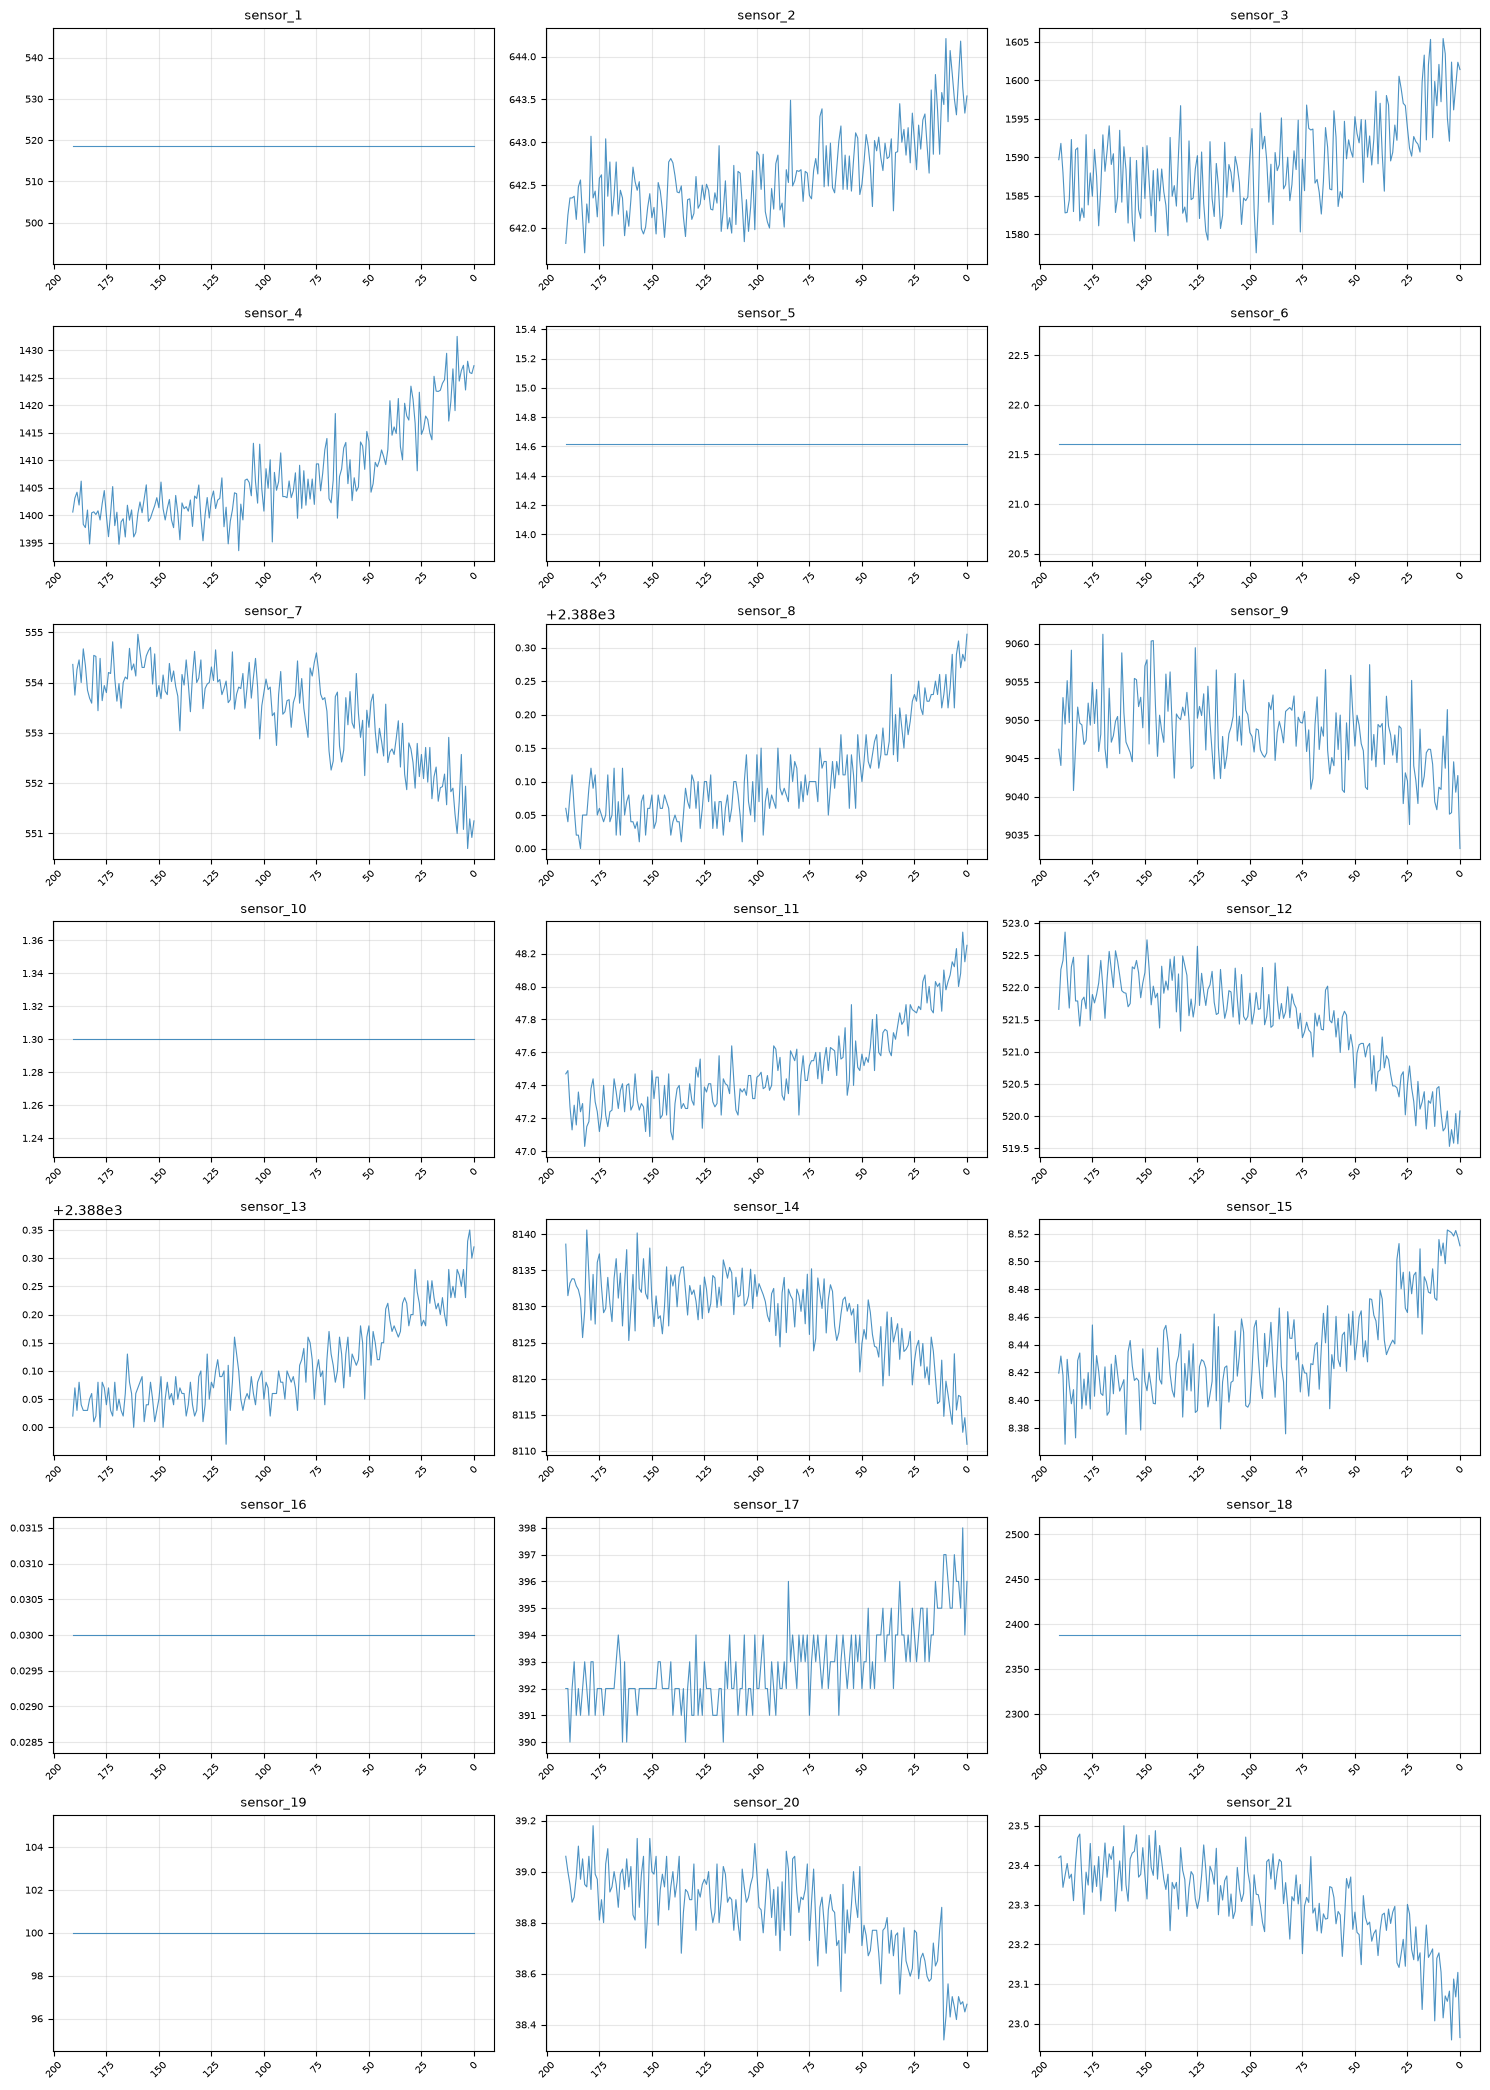

In [8]:
def plot_sensor_mean_and_noise(train_df: pd.DataFrame, n_engines: int = 1):
    sensor_cols = [c for c in train_df.columns if c.startswith('sensor_')]

    engine_ids = train_df['engine_id'].drop_duplicates().iloc[:n_engines]
    colors = plt.cm.tab10(np.linspace(0, 1, len(engine_ids)))

    n_cols = 3
    n_rows = -(-len(sensor_cols) // n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3 * n_rows))

    for ax, sensor in zip(axes.flat, sensor_cols):
        for engine_id, color in zip(engine_ids, colors):
            engine_df = train_df[train_df['engine_id'] == engine_id].sort_values('rul', ascending=False)
            ax.plot(engine_df['rul'], engine_df[sensor], color=color, alpha=0.8, linewidth=0.8)
        ax.set_title(sensor, fontsize=9)
        ax.tick_params(axis="x", rotation=45, labelsize=7)
        ax.tick_params(axis="y", labelsize=7)
        ax.grid(True, alpha=0.3)
        ax.invert_xaxis()  # rul decreases toward failure, so the axis reads left-to-right as the engine ages

    for ax in axes.flat[len(sensor_cols):]:
        ax.set_visible(False)

    fig.tight_layout()
    fig.savefig("sensor_mean_and_noise.png", dpi=150)
    plt.show()


plot_sensor_mean_and_noise(train_df)

# RUL distribution

How long engines run before failing (uncapped RUL, i.e. the last cycle reached by each engine).

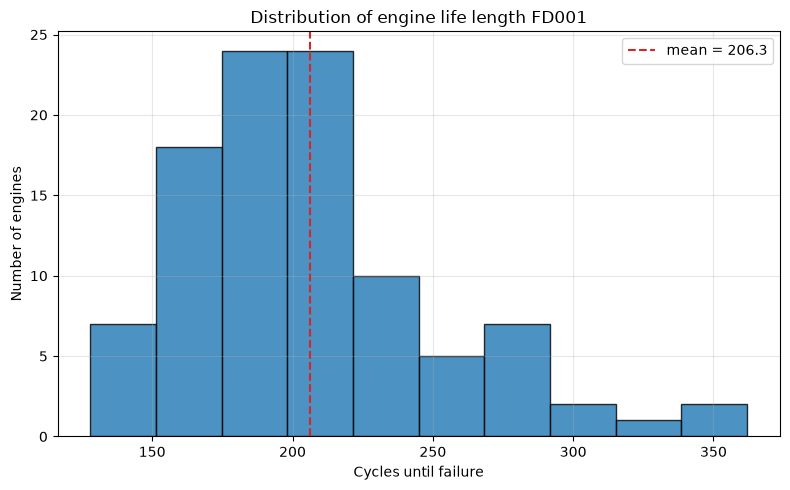

In [10]:
def plot_rul_distribution(df: pd.DataFrame):
    # Engines run until failure, so the last cycle reached equals the uncapped RUL at cycle 1.
    life_per_engine = df.groupby("engine_id")["cycle"].max()

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.hist(life_per_engine, color="#1f77b4", edgecolor="black", alpha=0.8)
    ax.axvline(life_per_engine.mean(), color="#d62728", linestyle="--",
               label=f"mean = {life_per_engine.mean():.1f}")
    ax.set_title("Distribution of engine life length FD001")
    ax.set_xlabel("Cycles until failure")
    ax.set_ylabel("Number of engines")
    ax.legend()
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    fig.savefig('../outputs/averange_life.png')
    plt.show()

    return life_per_engine


life_per_engine = plot_rul_distribution(train_df)

# Where does sensors change fastest?

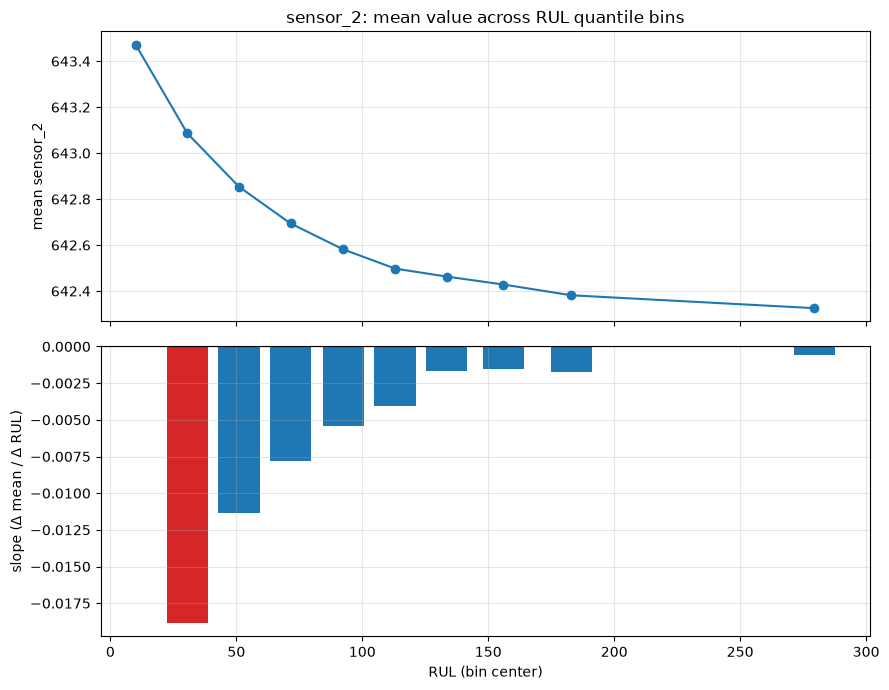

Steepest change in sensor_2 happens in RUL bin (20.0, 41.0]


In [11]:
def plot_sensor_slope_by_rul(df: pd.DataFrame, sensor: str, n_quantiles: int = 10):
    # Quantile bins keep a similar row count per bin despite RUL being right-skewed.
    rul_bin = pd.qcut(df["rul"], q=n_quantiles, duplicates="drop")
    mean_by_bin = df.groupby(rul_bin, observed=True)[sensor].mean().sort_index()
    bin_center = pd.Series(
        [interval.mid for interval in mean_by_bin.index], index=mean_by_bin.index
    )

    slope = mean_by_bin.diff() / bin_center.diff()
    steepest_bin = slope.abs().idxmax()

    fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)

    axes[0].plot(bin_center, mean_by_bin, marker="o", color="#1f77b4")
    axes[0].set_ylabel(f"mean {sensor}")
    axes[0].set_title(f"{sensor}: mean value across RUL quantile bins")
    axes[0].grid(True, alpha=0.3)

    bar_colors = ["#d62728" if b == steepest_bin else "#1f77b4" for b in slope.index]
    axes[1].bar(bin_center, slope, width=bin_center.diff().median() * 0.8, color=bar_colors)
    axes[1].axhline(0, color="black", linewidth=0.8)
    axes[1].set_xlabel("RUL (bin center)")
    axes[1].set_ylabel("slope (Δ mean / Δ RUL)")
    axes[1].grid(True, alpha=0.3)

    fig.tight_layout()
    fig.savefig('../outputs/Sensor_slope.png')
    plt.show()

    print(f"Steepest change in {sensor} happens in RUL bin {steepest_bin}")
    return slope


slope_sensor4 = plot_sensor_slope_by_rul(train_df, "sensor_2")
